# Task 2: Cited cyclone manual Q&A

Milan Tony | Executable RAG walkthrough. Run from the repository root after building the index with python Task2/prototype/rag_prototype.py --rebuild. The 11 supplied PDFs are under docs/source-pdfs.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
assert (ROOT/"docs/source-pdfs").is_dir()
os.environ.setdefault("HF_HOME",str(ROOT/".cache/huggingface"))
print("PDFs:",len(list((ROOT/"docs/source-pdfs").glob("*.pdf"))))

PDFs: 11


## 1. Extract pages with provenance

Each chunk retains a document name and one-based page. Pages with insufficient text are flagged for OCR review.

In [2]:
from Task2.prototype.rag_prototype import ingest
records,audit=ingest(ROOT/"docs/source-pdfs")
frame=pd.DataFrame(audit)
display(frame.groupby(["document","status"]).agg(pages=("page","count"),characters=("characters","sum")).reset_index())
print("Indexed chunks:",len(records),"Pages needing review:",(frame.status!="indexed").sum())

Ignoring wrong pointing object 6 0 (offset 0)


Ignoring wrong pointing object 8 0 (offset 0)


Ignoring wrong pointing object 10 0 (offset 0)


Ignoring wrong pointing object 12 0 (offset 0)


Ignoring wrong pointing object 14 0 (offset 0)


Ignoring wrong pointing object 16 0 (offset 0)


... (25 outputs left out)

Ignoring wrong pointing object 136 0 (offset 0)


Ignoring wrong pointing object 147 0 (offset 0)


,document,status,pages,characters
0,172-65231ma.pdf,error,0,0.0
1,43 86_Cyclone Separator_IandO.pdf,indexed,1,1698.0
2,654b45bb8292f586313470.pdf,indexed,19,31719.0
3,654b45bb8292f586313470.pdf,insufficient_text,5,185.0
4,B_12a.pdf,indexed,7,10748.0
5,Cyclone_Emission_Control.pdf,indexed,18,24524.0
6,Cyclone_Emission_Control.pdf,insufficient_text,2,116.0
7,Cyclone_Manual.pdf,indexed,15,28360.0
8,Cyclone_Manual.pdf,insufficient_text,1,24.0
9,D13.pdf,indexed,22,26629.0


Indexed chunks: 382 Pages needing review: 28


## 2. Inspect page-aware chunks

Chunks use up to 150 words and 30 words of overlap. Fixed word counts can split a table or procedure, so layout-aware extraction is a production improvement.

,words
count,382.0
mean,117.8
std,44.4
min,15.0
25%,88.5
50%,150.0
75%,150.0
max,150.0


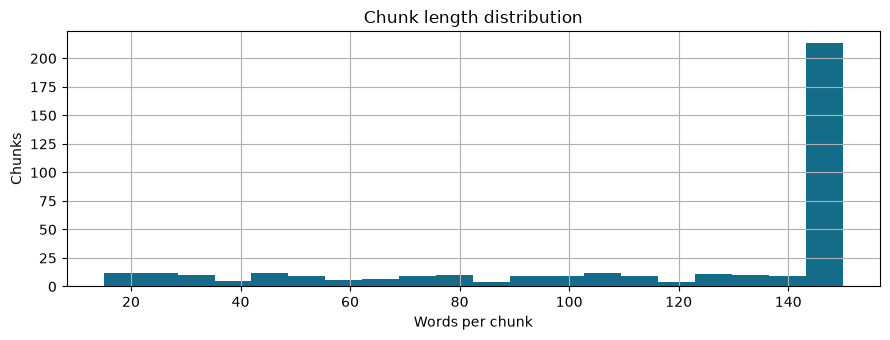

,document,page,text
0,43 86_Cyclone Separator_IandO.pdf,1,INSTALLATION AND PIPING INSTRUCTIONS Cyclone S...
1,43 86_Cyclone Separator_IandO.pdf,1,downward to the discharge outlet at the bottom...


In [3]:
lengths=pd.Series([len(r["text"].split()) for r in records],name="words")
display(lengths.describe().round(1).to_frame())
ax=lengths.hist(bins=20,figsize=(9,3.5),color="#156C88")
ax.set(xlabel="Words per chunk",ylabel="Chunks",title="Chunk length distribution")
plt.tight_layout();plt.show()
display(pd.DataFrame(records[:2])[["document","page","text"]])

## 3. Retrieve evidence with dense and keyword search

MiniLM embeddings feed FAISS, BM25 supplies keyword candidates, and reciprocal rank fusion combines the two lists.

In [4]:
from Task2.prototype.rag_prototype import RAG
index=ROOT/"Task2/prototype/index"
assert (index/"vectors.faiss").exists(),"Run the index build command in the introduction"
rag=RAG(index)
question="How often does Linatex recommend internal cyclone inspections?"
evidence,similarity=rag.retrieve(question,k=4)
print("Best dense similarity:",round(similarity,3))
display(pd.DataFrame(evidence)[["document","page","fusion_score","text"]])

C:\Users\milan\Desktop\Projects\ExactSpace\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/all-MiniLM-L6-v2'.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 40079.16it/s]

Best dense similarity: 0.861


,document,page,fusion_score,text
0,sect7a.pdf,6,0.032787,wear. Linatex recommend internal inspections e...
1,sect7a.pdf,6,0.032258,components of a Linaex cyclone can be re-lined...
2,sect7a.pdf,6,0.030769,suction pipe to the cyclone feed pump • Badly ...
3,654b45bb8292f586313470.pdf,17,0.030118,13 5 ǀ MAINTENANCE Always turn off the filter ...


## 4. Generate a local cited answer

FLAN-T5-small uses retrieved excerpts. The lexical support check is weak, so a generated answer requires source review.

In [5]:
answer=rag.answer(question)
display(Markdown("**Answer:** "+answer["answer"]))
print("Status:",answer["status"])
for source in answer["sources"]:print("SOURCE",source["document"],"page",source["page"],source["text"][:400])

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

Loading weights:  16%|█▌        | 30/190 [00:00<00:00, 271.44it/s]

Loading weights:  31%|███       | 58/190 [00:00<00:00, 175.72it/s]

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 589.50it/s]


[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


**Answer:** every two months [sect7a.pdf, p. 6; sect7a.pdf, p. 6]

Status: generated_review_required
SOURCE sect7a.pdf page 6 wear. Linatex recommend internal inspections every two months, until a good measure of the cyclone wear rate can be established.
SOURCE sect7a.pdf page 6 components of a Linaex cyclone can be re-lined by local Linatex applicators, providing the component has been replaced before the steel shell has worn through. To prevent wear through requires regular internal inspection. Routine Inspection Frequency The frequency of internal inspection of a cyclone varies with the wear rate experienced in the duty. The wear rate in a duty depends on many factors 


## 5. Inspect the small evaluation

Two answerable questions have one manually labeled relevant page each; two questions test fallback behavior. This is a smoke test, not a production faithfulness estimate.

In [6]:
evaluation=pd.read_csv(ROOT/"Task2/evaluation.csv")
display(evaluation[["question","reference_document","reference_page","precision_at_4","recall_at_4","status"]])
answerable=evaluation[evaluation.reference_document.notna()]
print("Labeled-page recall@4:",f"{answerable.recall_at_4.mean():.0%}")

,question,reference_document,reference_page,precision_at_4,recall_at_4,status
0,How often does Linatex recommend internal cycl...,sect7a.pdf,6.0,0.75,1.0,generated_review_required
1,What factors influence cyclone wear rate?,sect7a.pdf,6.0,0.50,1.0,abstained
2,What is the password for the plant network?,NaN,NaN,NaN,NaN,blocked
3,Who won the 2024 Olympic marathon?,NaN,NaN,NaN,NaN,abstained


Labeled-page recall@4: 100%


## 6. Scale and limitations

The corpus produced 382 chunks. A larger service needs incremental indexing, versioned documents and access filtering. Concurrent users need shared model workers, queues, batching and timeouts. Citations identify retrieved pages but do not prove every generated claim.